In [5]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

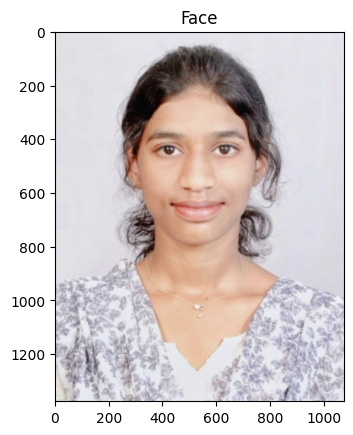

In [6]:
# Load the Face Image
faceImage = cv2.imread('pass photo.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [7]:
faceImage.shape

(1376, 1076, 3)

In [8]:
#resized_faceImage.shape
faceImage.shape

(1376, 1076, 3)

Text(0.5, 1.0, 'glassPNG')

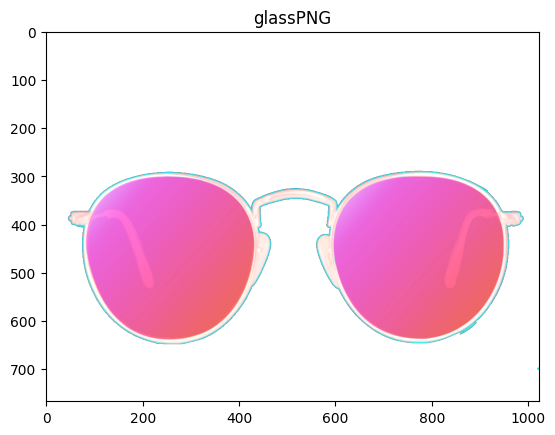

In [19]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('glassl.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [20]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [21]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

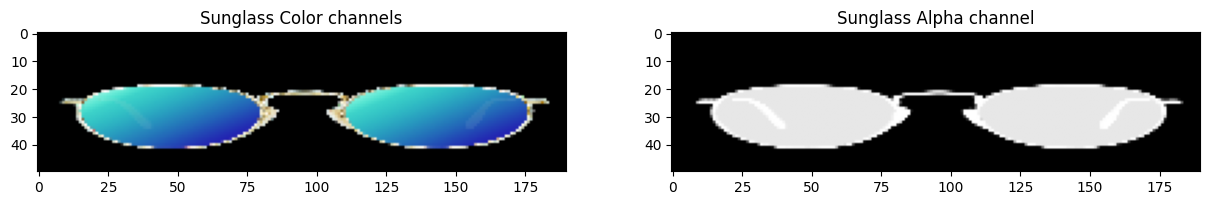

In [22]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

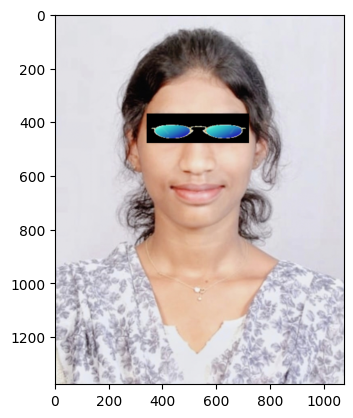

In [23]:
# Make a copy
#faceWithGlassesNaive = resized_faceImage.copy()
faceWithGlassesNaive = faceImage.copy()

# Replace the eye region with the sunglass image
glassBGR = cv2.resize(glassBGR, (380, 110))
faceWithGlassesNaive[370:480, 340:720] = glassBGR

plt.imshow(faceWithGlassesNaive[...,::-1])

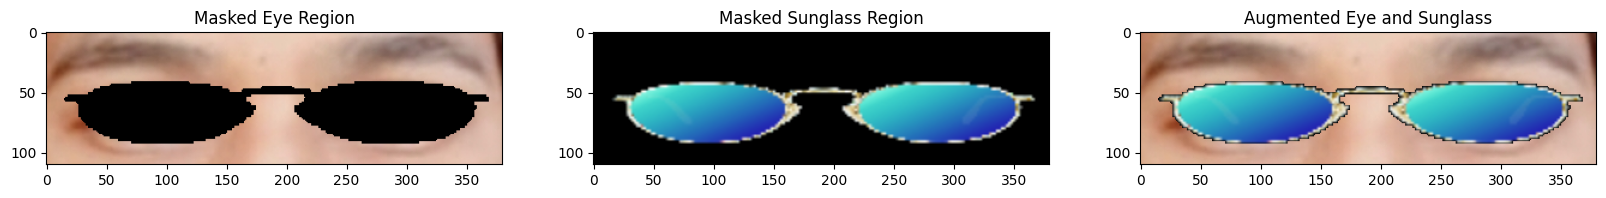

In [30]:
# Resize the sunglasses to match the eye region
glassBGR = cv2.resize(glassBGR, (380, 110))
# Convert sunglasses image to grayscale
glassGray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)

# Create binary mask
# Black background = 0
# Sunglasses = 255
_, glassMask1 = cv2.threshold(glassGray, 10, 255, cv2.THRESH_BINARY)

# Make the mask 3-channel
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Convert mask values from [0,255] to [0,1]
glassMask = np.uint8(glassMask / 255)

faceWithGlassesArithmetic = faceImage.copy()
eyeROI = faceWithGlassesArithmetic[370:480, 340:720]
# Inverse mask
inverseMask = 1 - glassMask

# Remove the area where the sunglasses will be placed
maskedEye = cv2.multiply(eyeROI, inverseMask)
maskedGlass = cv2.multiply(glassBGR, glassMask)
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)
faceWithGlassesArithmetic[370:480, 340:720] = eyeRoiFinal
plt.figure(figsize=[20, 20]);plt.subplot(131);plt.imshow(maskedEye[..., ::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[..., ::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[..., ::-1]);plt.title("Augmented Eye and Sunglass")
plt.show()

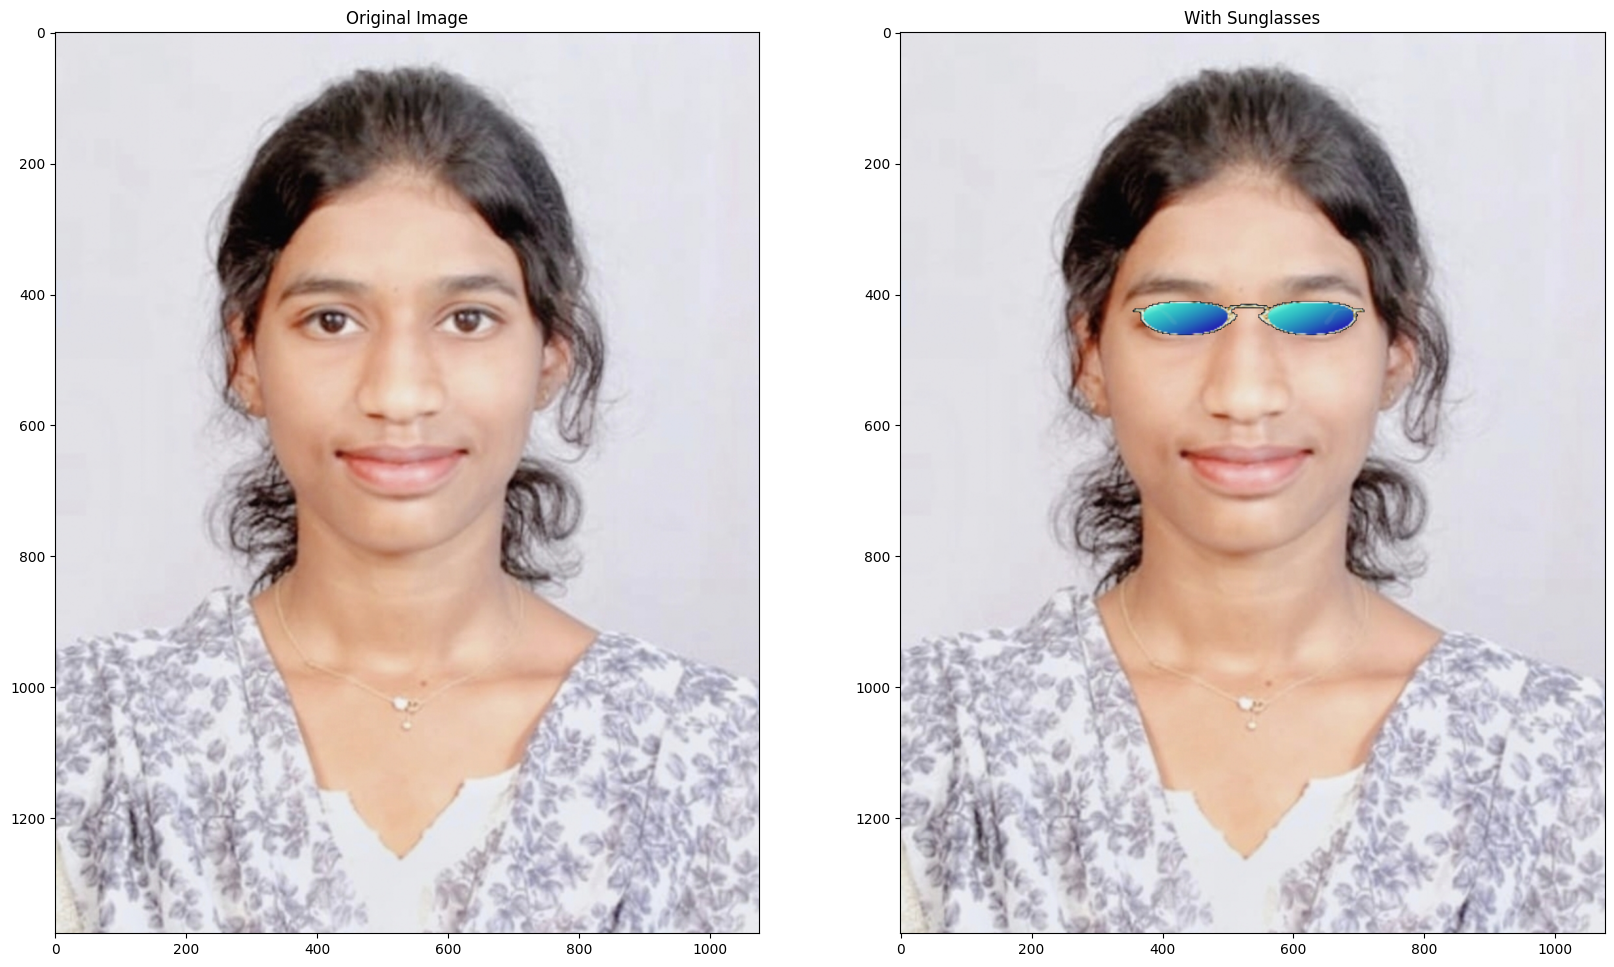

In [31]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic[370:480,340:720] = eyeRoiFinal

# Display the final result
plt.figure(figsize=[20,20]);
plt.subplot(121);plt.imshow(faceImage[:,:,::-1]); plt.title("Original Image");
plt.subplot(122);plt.imshow(faceWithGlassesArithmetic[:,:,::-1]);plt.title("With Sunglasses");